# Gear dynamics 05: bearings, lateral DOFs and dynamic bearing forces

So far the gear centres were fixed in space, and the bearing forces of notebook 01 were
pure statics. Real bearings and housings are compliant, typically 1–5·10⁸ N/m per ball
bearing, i.e. about as stiff as the mesh. Once the gear centres can move:

* the **mesh deflection** picks up a lateral part: $\delta = r_{b1}\theta_1 - r_{b2}\theta_2 + (\mathbf u_1 - \mathbf u_2)\cdot\mathbf n$;
* the **centre distance** breathes, so the backlash changes under load;
* the tooth force excites **lateral modes**, and the bearings pass a *dynamic* force to the
  housing. That is the structure-borne noise path.

Each gear gets an isotropic bearing spring $k_b$ (both bearings of a shaft combined, as seen
at the gear) and translational mass (gear plus its share of the shaft). 6 DOF:
$(x_1, y_1, \theta_1, x_2, y_2, \theta_2)$.

**Experiments:** **A** static load: series stiffness and backlash change · **B** modes against
bearing stiffness · **C** preload-and-release with bearings · **D** running at speed: what
the housing sees.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import geardyn as gd

gd.style()
gp = gd.GearPair(backlash=60e-6, m1_extra=0.3, m2_extra=0.6)
T1 = 40.0
F0 = T1 / gp.rb1
kb = 3e8


def model(kb1=kb, kb2=kb, zb=0.03, **kw):
    """lateral pair with bearing damping ratio zb on each gear's lateral mode"""
    cb1 = 2 * zb * np.sqrt(kb1 * gp.m1); cb2 = 2 * zb * np.sqrt(kb2 * gp.m2)
    kw.setdefault("contact", "backlash")
    return gd.lateral_pair(gp, kb1, kb2, cb1, cb2, **kw)


print(gp.summary())
print(f"bearing stiffness per gear k_b = {kb/1e6:.0f} N/um, translational masses m1 = {gp.m1:.2f} kg, m2 = {gp.m2:.2f} kg")

z1 / z2                                 24 / 48  -
ratio i = z2/z1                           2.000  -
module                                     2.50  mm
pressure angle                             20.0  deg
pitch radii r1 / r2               30.00 / 60.00  mm
base radii rb1 / rb2              28.19 / 56.38  mm
centre distance a                         90.00  mm
base pitch pb                             7.380  mm
contact ratio eps_alpha                   1.675  -
J1 / J2                   1.498e-04 / 2.397e-03  kg m^2
m1 / m2                           0.633 / 1.932  kg
equivalent mass m_eq                     0.1508  kg
mesh stiffness k (mean)                   316.3  N/um
mesh damping c                            690.6  N s/m
mesh natural frequency                     7288  Hz
backlash j_n                                 60  um
bearing stiffness per gear k_b = 300 N/um, translational masses m1 = 0.63 kg, m2 = 1.93 kg


## 1  How the lateral DOFs enter the mesh

The drive-flank penetration and its gradient with respect to
$\mathbf q = (x_1, y_1, \theta_1, x_2, y_2, \theta_2)$:

$$p_d = r_{b1}\theta_1 - r_{b2}\theta_2 + (x_1 - x_2)\sin\alpha + (y_1 - y_2)\cos\alpha - \tfrac{j_n}{2}$$
$$\mathbf g_d = \partial p_d/\partial\mathbf q = (\sin\alpha,\ \cos\alpha,\ r_{b1},\ -\sin\alpha,\ -\cos\alpha,\ -r_{b2})$$

The generalized mesh force is $-F_d\,\mathbf g_d$: the same vector distributes the force into
torques *and* bearing loads, which is the virtual-work view of notebook 01's statics. The
coast flank has $\cos\alpha \to -\cos\alpha$ in the lateral terms. Moving the centres apart
along $x$ reduces **both** penetrations: that is the backlash opening with the centre distance.

In [2]:
m = model()
print("labels:", m.labels)
print("g_drive =", np.round(m.meshes[0].g(m.n, "drive"), 4))
print("g_coast =", np.round(m.meshes[0].g(m.n, "coast"), 4))

labels: ['x1', 'y1', 'th1', 'x2', 'y2', 'th2']
g_drive = [ 0.342   0.9397  0.0282 -0.342  -0.9397 -0.0564]
g_coast = [ 0.342  -0.9397 -0.0282 -0.342   0.9397  0.0564]


## 2  Experiment A: static load, series stiffness, backlash change

Clamp gear 2 in rotation (a load), apply $T_1$ to gear 1. Along the LOA the mesh and the two
bearings act **in series**:

$$\frac{1}{k_\text{eff}} = \frac1k + \frac1{k_{b1}} + \frac1{k_{b2}}$$

The bearings move the centres apart by $\Delta a = F\sin\alpha\,(1/k_{b1}+1/k_{b2})$, which opens
the backlash by $2\Delta a\sin\alpha$.

In [3]:
mA = model()
mA.fix("th2")
Q = np.zeros(mA.n); Q[mA.index("th1")] = T1
q = mA.static(Q)
x1, y1, th1, x2, y2 = [q[mA.index(d)] for d in ["x1", "y1", "th1", "x2", "y2"]]
k_eff = 1 / (1 / gp.k_mesh + 2 / kb)
print(f"pinion rotation at the LOA: r_b1*th1 = {gp.rb1*th1*1e6:.2f} um; F/k_eff = {(F0/k_eff + gp.backlash/2)*1e6:.2f} um "
      f"(incl. half backlash {gp.backlash/2*1e6:.0f} um)")
print(f"  of which mesh {F0/gp.k_mesh*1e6:.2f} um and bearings {2*F0/kb*1e6:.2f} um -> k_eff = {k_eff/1e6:.0f} N/um vs k = {gp.k_mesh/1e6:.0f} N/um")
print(f"gear 1 centre moves ({x1*1e6:.2f}, {y1*1e6:.2f}) um, gear 2 ({x2*1e6:.2f}, {y2*1e6:.2f}) um")
da = x2 - x1
print(f"centre distance +{da*1e6:.2f} um  ->  backlash +{2*da*np.sin(gp.alpha)*1e6:.2f} um")
R = mA.bearings[0].k * np.array([-x1, -y1])
print(f"bearing reaction on shaft 1: ({R[0]:.0f}, {R[1]:.0f}) N = F0*n_d = ({F0*np.sin(gp.alpha):.0f}, {F0*np.cos(gp.alpha):.0f}) N")

pinion rotation at the LOA: r_b1*th1 = 43.95 um; F/k_eff = 43.95 um (incl. half backlash 30 um)
  of which mesh 4.49 um and bearings 9.46 um -> k_eff = 102 N/um vs k = 316 N/um
gear 1 centre moves (-1.62, -4.44) um, gear 2 (1.62, 4.44) um
centre distance +3.24 um  ->  backlash +2.21 um
bearing reaction on shaft 1: (485, 1333) N = F0*n_d = (485, 1333) N


Under load the bearings double the compliance along the LOA. The torsional stiffness
a drivetrain model "sees" is $k_\text{eff}\,r_{b1}^2$, not $k\,r_{b1}^2$. The static reaction
is still exactly $F\,\mathbf n_d$, as in notebook 01: statics doesn't care about stiffness.

## 3  Experiment B: modes against bearing stiffness

Linearize on the drive flank (mean $k$) and sweep $k_b$ (same on both gears). Colour each
mode by the share of its strain energy that sits in the **mesh**. Then compare with two
limits:

* rigid bearings: the torsional mesh mode of notebook 02, $\sqrt{k/m_{eq}}$;
* very soft bearings: the gears float, and their **translational** inertia adds to the
  rotational one in series: $1/m_\text{eff} = r_{b1}^2/J_1 + r_{b2}^2/J_2 + 1/m_1 + 1/m_2$. The mesh
  mode goes **up**. Softer bearings, higher mesh frequency: the opposite of the static
  intuition.

modes at k_b = 3e8 N/m [Hz]: [   0. 1896. 1983. 3099. 3465. 8524.]


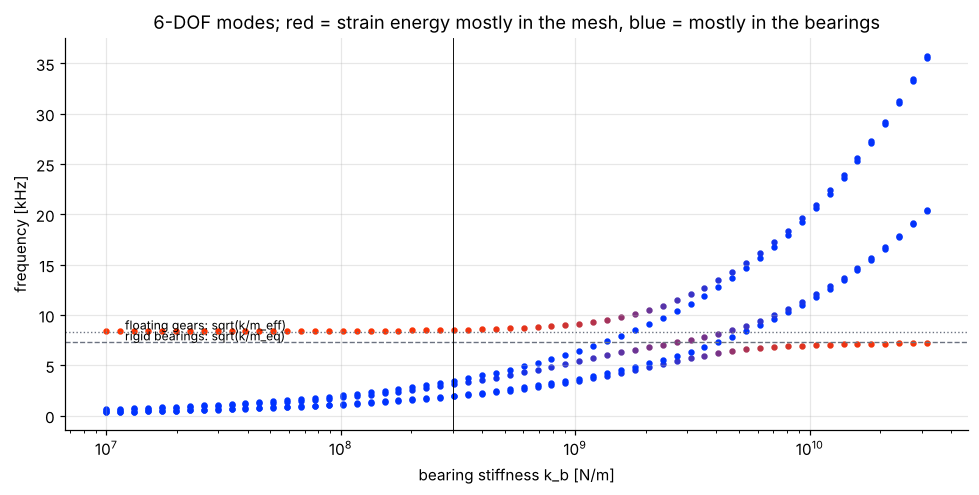

In [4]:
kbs = np.logspace(7, 10.5, 60)
fig, ax = plt.subplots(figsize=(9, 4.6))
for kbi in kbs:
    mm = model(kbi, kbi)
    f, V = mm.linear_modes()
    Km = mm.mesh_stiffness_matrix()
    _, K, _ = mm.matrices()
    for j in range(1, len(f)):
        v = V[:, j]
        share = float(np.clip((v @ Km @ v) / (v @ (K + Km) @ v), 0, 1))
        ax.scatter(kbi, f[j] / 1e3, c=[[share, 0.2, 1 - share]], s=10)
meff = 1 / (gp.rb1**2 / gp.J1 + gp.rb2**2 / gp.J2 + 1 / gp.m1 + 1 / gp.m2)
ax.axhline(gp.f_n / 1e3, color=gd.C["grey"], ls="--", lw=0.9)
ax.text(1.2e7, gp.f_n / 1e3 + 0.2, "rigid bearings: sqrt(k/m_eq)", fontsize=8)
ax.axhline(np.sqrt(gp.k_mesh / meff) / 2 / np.pi / 1e3, color=gd.C["grey"], ls=":", lw=0.9)
ax.text(1.2e7, np.sqrt(gp.k_mesh / meff) / 2 / np.pi / 1e3 + 0.2, "floating gears: sqrt(k/m_eff)", fontsize=8)
ax.axvline(kb, color="k", lw=0.6)
ax.set_xscale("log"); ax.set_xlabel("bearing stiffness k_b [N/m]"); ax.set_ylabel("frequency [kHz]")
ax.set_title("6-DOF modes; red = strain energy mostly in the mesh, blue = mostly in the bearings")
plt.tight_layout()

f, V = model().linear_modes()
print("modes at k_b = 3e8 N/m [Hz]:", np.round(f, 0))

Mode shapes at the reference bearing stiffness: arrows show the centre motion, the labels the
rotation (printed as $r_b\theta$). Lateral modes come in near-pairs, because the bearings are
isotropic but the mesh couples only along $\mathbf n_d$.

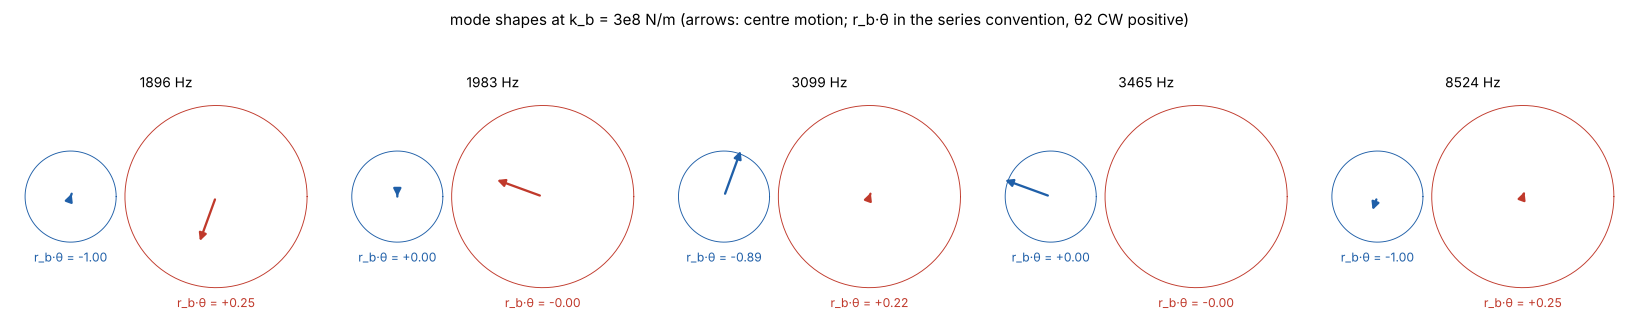

In [5]:
fig, axs = plt.subplots(1, 5, figsize=(15, 3.2))
mm = model()
for ax, j in zip(axs, range(1, 6)):
    v = V[:, j] / np.max(np.abs(V[:, j] * np.r_[1, 1, gp.rb1, 1, 1, gp.rb2]))
    for (cx, ix, iy, ith, rb, col) in [(0, 0, 1, 2, gp.rb1, gd.C["blue"]), (gp.a, 3, 4, 5, gp.rb2, gd.C["red"])]:
        t = np.linspace(0, 2 * np.pi, 100)
        ax.plot(cx + rb * np.cos(t), rb * np.sin(t), color=col, lw=0.6)
        ax.annotate("", xy=(cx + 0.03 * v[ix], 0.03 * v[iy]), xytext=(cx, 0),
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=1.5))
        ax.text(cx, -rb - 0.012, f"r_b·θ = {v[ith]*rb:+.2f}", color=col, ha="center", fontsize=8)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{f[j]:.0f} Hz", fontsize=9)
plt.suptitle("mode shapes at k_b = 3e8 N/m (arrows: centre motion; r_b·θ in the series convention, θ2 CW positive)", fontsize=10)
plt.tight_layout()

## 4  Experiment C: preload and release, with bearings

The notebook 04 experiment again: gear 2 clamped in rotation, 40 N m on gear 1, 60 µm
backlash, release. The bearing springs are preloaded too, so they hold strain energy that
comes out alongside the mesh energy. Watch the **bearing-force vector**: it jumps between the
drive direction $\mathbf n_d$ and the coast direction $\mathbf n_r$ (140° apart, notebook 01),
while the gear centre traces an orbit.

energy residual 2.6e-07 V0; preload energy: 9.89 mJ with bearings vs 3.18 mJ rigid


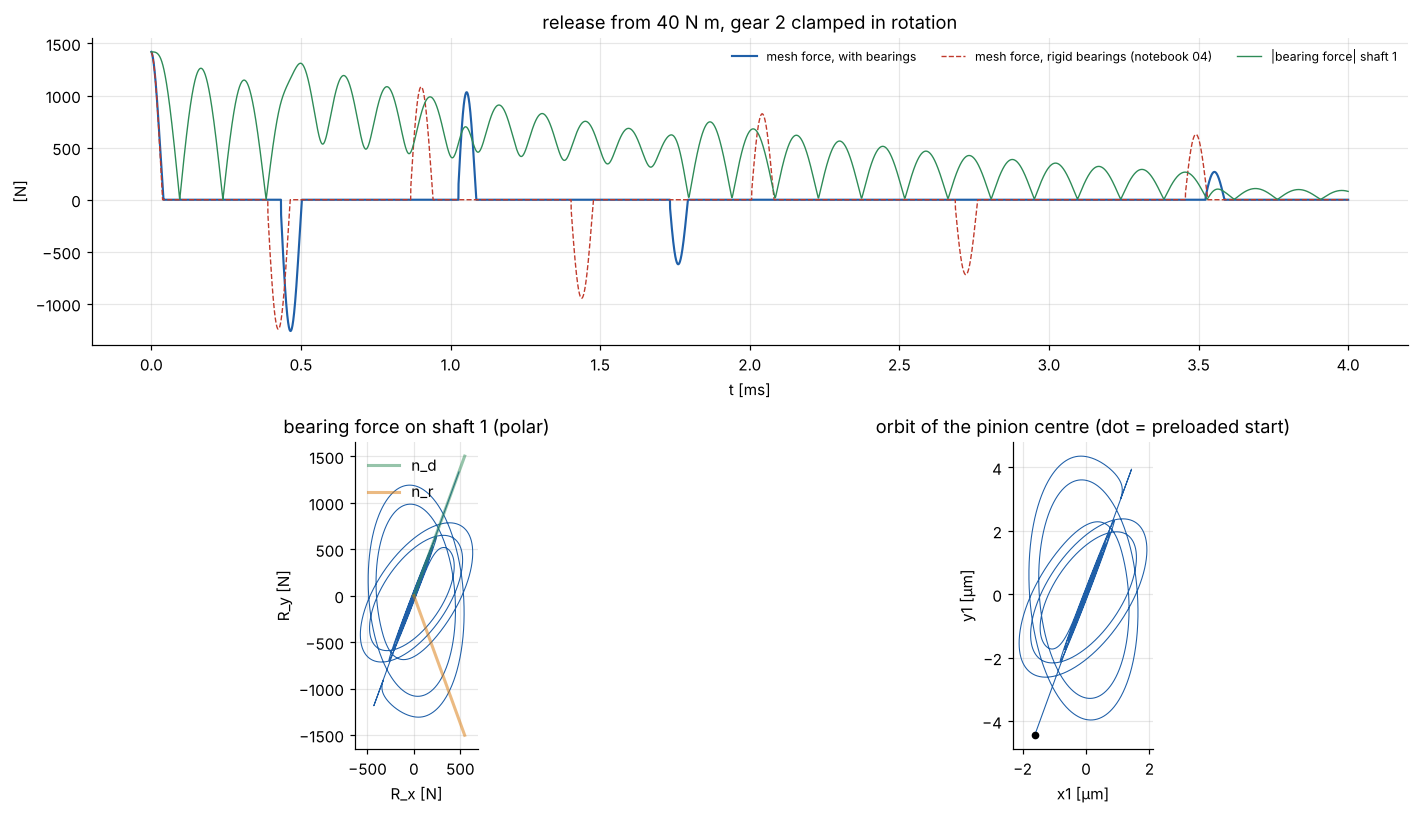

In [6]:
mC = model()
mC.fix("th2")
Q = np.zeros(mC.n); Q[mC.index("th1")] = T1
q0 = mC.static(Q)
rC = mC.simulate(4e-3, q0=q0, n_out=8000)
R1 = rC.bearing["B1"]
mT = gd.torsional_pair(gp, contact="backlash"); mT.fix("th2")
rT = mT.simulate(4e-3, q0=mT.static(np.r_[T1, 0]), n_out=8000)

fig = plt.figure(figsize=(13, 7.5))
ax1 = fig.add_subplot(2, 2, (1, 2))
ax1.plot(rC.t * 1e3, rC.mesh[0]["F"], label="mesh force, with bearings")
ax1.plot(rT.t * 1e3, rT.mesh[0]["F"], "--", lw=0.9, label="mesh force, rigid bearings (notebook 04)")
ax1.plot(rC.t * 1e3, np.hypot(*R1), color=gd.C["green"], lw=0.9, label="|bearing force| shaft 1")
ax1.set_xlabel("t [ms]"); ax1.set_ylabel("[N]"); ax1.legend(fontsize=8, ncol=3)
ax1.set_title("release from 40 N m, gear 2 clamped in rotation")
ax2 = fig.add_subplot(2, 2, 3)
ax2.plot(R1[0], R1[1], lw=0.7)
for sgn, lab, col in [(1, "n_d", gd.C["green"]), (-1, "n_r", gd.C["orange"])]:
    ax2.plot([0, 1600 * np.sin(gp.alpha)], [0, sgn * 1600 * np.cos(gp.alpha)], color=col, lw=2, alpha=0.5, label=lab)
ax2.set_aspect("equal"); ax2.set_xlabel("R_x [N]"); ax2.set_ylabel("R_y [N]"); ax2.legend()
ax2.set_title("bearing force on shaft 1 (polar)")
ax3 = fig.add_subplot(2, 2, 4)
ax3.plot(rC["x1"] * 1e6, rC["y1"] * 1e6, lw=0.7)
ax3.plot(rC["x1"][0] * 1e6, rC["y1"][0] * 1e6, "ko", ms=4)
ax3.set_aspect("equal"); ax3.set_xlabel("x1 [µm]"); ax3.set_ylabel("y1 [µm]")
ax3.set_title("orbit of the pinion centre (dot = preloaded start)")
plt.tight_layout()
print(f"energy residual {np.max(np.abs(rC.energy_residual))/rC.V[0]:.1e} V0; preload energy: "
      f"{rC.V[0]*1e3:.2f} mJ with bearings vs {rT.V[0]*1e3:.2f} mJ rigid")

* The preload energy triples (each bearing spring stores about as much as the mesh), so the
  gear leaves faster and the impacts are harder.
* The bearing force does not just follow the mesh force. The gear centre keeps oscillating
  on its bearing while the teeth are apart, so the housing feels forces *between* impacts
  as well.
* In the polar plot the force follows $\mathbf n_d$ or $\mathbf n_r$ only while a flank is in
  contact. In between it rotates freely with the lateral vibration.

## 5  Experiment D: running at speed, what the housing sees

Steady running under 40 N m with time-varying mesh stiffness (notebook 03). Gear 1 is
**driven at constant speed** (prescribed), and gear 2 carries a heavy load inertia and the
reaction torque $i\,T_1$. The tooth force ripple goes into both bearings. For three bearing
stiffnesses, plot the dynamic bearing force (peak-peak of the component along $\mathbf n_d$,
relative to the static force) against speed.

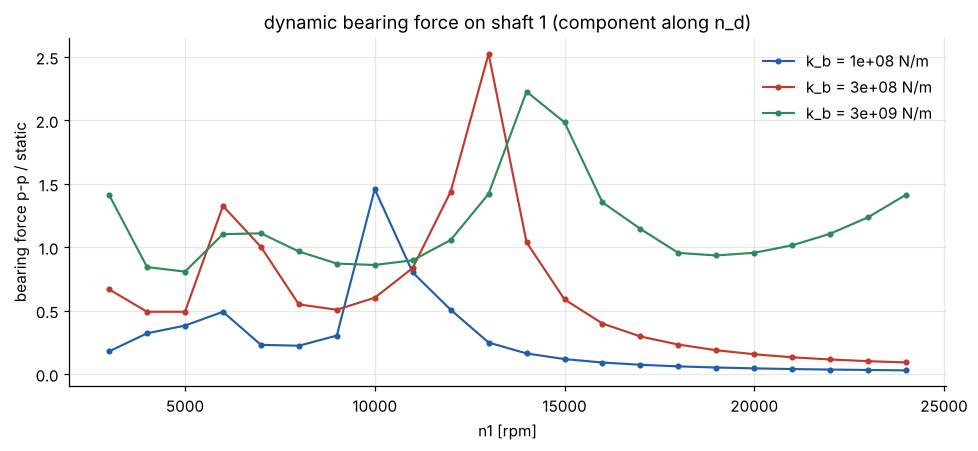

In [7]:
gD = gp.with_(J2_extra=0.05)


def run(n1, kb_, T1=T1):
    mD = gd.lateral_pair(gD, kb_, kb_, 2 * 0.05 * np.sqrt(kb_ * gD.m1), 2 * 0.05 * np.sqrt(kb_ * gD.m2),
                         contact="backlash", stiffness="tv")
    W = n1 * 2 * np.pi / 60
    mD.prescribe("th1", lambda t: W * t, lambda t: W, lambda t: 0.0)
    mD.add_load("th2", lambda t, q, v: -gD.i * T1)
    Q = np.zeros(mD.n); Q[mD.index("th2")] = -gD.i * T1
    q0 = mD.static(Q); v0 = np.zeros(mD.n); v0[mD.index("th2")] = W / gD.i
    fz = gD.f_mesh(n1)
    t_end = 30 / fz + 12e-3
    t_ev = np.linspace(t_end - 10 / fz, t_end, 601)
    return mD.simulate(t_end, q0=q0, v0=v0, t_eval=t_ev, method="RK45", rtol=1e-7)


speeds = np.linspace(3000, 24000, 22)
nd = np.array([np.sin(gp.alpha), np.cos(gp.alpha)])
fig, ax = plt.subplots(figsize=(9, 4.2))
for kb_, col in [(1e8, gd.C["blue"]), (3e8, gd.C["red"]), (3e9, gd.C["green"])]:
    amp = []
    for n in speeds:
        r = run(n, kb_)
        Rn = nd @ r.bearing["B1"]
        amp.append(np.ptp(Rn) / F0)
    ax.plot(speeds, amp, "o-", ms=3, color=col, label=f"k_b = {kb_:.0e} N/m")
ax.set_xlabel("n1 [rpm]"); ax.set_ylabel("bearing force p-p / static")
ax.set_title("dynamic bearing force on shaft 1 (component along n_d)")
ax.legend()
plt.tight_layout()

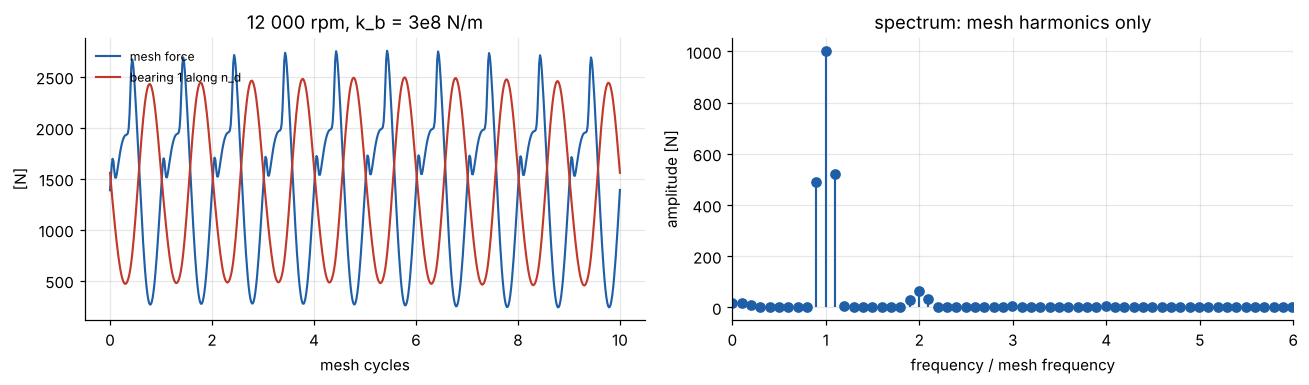

In [8]:
r = run(12000, 3e8)
fz = gD.f_mesh(12000)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
tt = (r.t - r.t[0]) * fz
ax[0].plot(tt, r.mesh[0]["F"], label="mesh force")
ax[0].plot(tt, nd @ r.bearing["B1"], label="bearing 1 along n_d")
ax[0].set_xlabel("mesh cycles"); ax[0].set_ylabel("[N]"); ax[0].legend(fontsize=8)
ax[0].set_title("12 000 rpm, k_b = 3e8 N/m")
x = nd @ r.bearing["B1"]; x = x - x.mean()
X = np.abs(np.fft.rfft(x * np.hanning(len(x)))) * 4 / len(x)
fr = np.fft.rfftfreq(len(x), r.t[1] - r.t[0])
ax[1].stem(fr / fz, X, basefmt=" ")
ax[1].set_xlim(0, 6); ax[1].set_xlabel("frequency / mesh frequency"); ax[1].set_ylabel("amplitude [N]")
ax[1].set_title("spectrum: mesh harmonics only")
plt.tight_layout()

The bearing stiffness moves the resonances: soft bearings shift the coupled
lateral-torsional modes into the mid speed range, while stiff bearings leave the mesh mode
alone but pass the tooth-force ripple straight to the housing. There is no "free"
choice. Housing and bearing stiffness are tuning parameters of gear noise, just as tip relief
is.

## 6  Take-aways

* Lateral DOFs enter through the gradient vector $\mathbf g$. The same vector turns the
  tooth force into torques and bearing loads.
* Statically, bearings act in series with the mesh: $1/k_\text{eff} = 1/k + 1/k_{b1} + 1/k_{b2}$.
  Under load the centre distance grows and the backlash opens.
* Dynamically the gears' translational inertia acts in series too. Softer bearings can
  **raise** the mesh-mode frequency.
* Bearing forces are not just "mesh force times geometry" once lateral modes are excited:
  the gear centre vibrates on its bearing between impacts and adds force at its own frequencies.

## Exercises

1. Make the bearings anisotropic (`add_bearing` with separate x/y springs via `add_spring`).
   Which mode pairs split?
2. Experiment C with stiff bearings (3e9 N/m): does it converge to the notebook 04 result?
3. Add a third body: the housing as a mass on mounts between the two bearing springs.
   How does the force *into the mounts* differ from the bearing force?
4. Gravity: add a constant load $-m g$ on `y1`, `y2`. At low torque, which flank is loaded?